# Project

### Group L : Taïs Thomas, Marouchka Heck, Marie-Caroline Bilocq

### Question 1
Compute the density ($g.cm^{-3}$), accessible surface area - ASA ($A^2$), accessible probe-occupiable volume - POAV ($A^3$) and porosity of the different structures by running pore analysis.

We first characterize the pore properties of the five MOF structures: Mg-MOF-74, NOTT-300, UTSA-20, UTSA-80 and ZIF-8.
For each structure, we compute the density, accessible surface area (ASA), accessible probe-occupiable volume (POAV), and porosity using Zeo++.
A probe radius of 1.525 Å is used.

| Structure | Density ($g.cm^{-3}$) | ASA ($A^2$) | POAV ($A^3$) | Porosity |
|---|---:|---:|---:|---:|
| Mg-MOF-74 | 0.886275 | 222.828 | 837.198 | 0.61368 |
| NOTT-300 | 1.03926 | 453.452 | 1297.11 | 0.48999 |
| UTSA-20 | 0.882399 | 1307.51 | 3575.36 | 0.62907 |
| UTSA-80 | 0.678215 | 3114.62 | 9619.78 | 0.66798 |
| ZIF-8 | 0.909567 | 1482.95 | 2770.55 | 0.55568 |

For the porosity, we use the POAV volume fraction, since it represents the fraction of the unit-cell volume that is accessible to the probe used in the pore analysis.

Among the five structures, UTSA-80 has the lowest density and the highest ASA, POAV and porosity. UTSA-20 also shows a relatively high porosity, followed by Mg-MOF-74, ZIF-8 and NOTT-300. NOTT-300 has the highest density and the lowest porosity of the structures considered.

### Question 2
Compute the Henry coefficients for $CO_2$ and $N_2$ at 25°C. Rank the structures based on their affinity for $CO_2$.

The Henry coefficients $K_H$ of $CO_2$ and $N_2$ were computed at 298 K for each MOF and were reported in the table below.

| Structure | $K_H$ for $CO_2$ ($mol \cdot kg^{-1} \cdot Pa^{-1}$)|$K_H$ for $N_2$ ($mol \cdot kg^{-1} \cdot Pa^{-1}$)|
|---|---:|---:|
| Mg-MOF-74 |8.41724 × $10^{-5}$ | 3.34155 × $10^{-6}$ |
| NOTT-300 | 1.84886 × $10^{-4}$ | 1.05363 × $10^{-5}$ |
| UTSA-20 | 4.08252 × $10^{-5}$ | 4.38632 × $10^{-6}$ |
| UTSA-80 | 1.70246 × $10^{-5}$ | 3.33304 × $10^{-6}$ |
| ZIF-8 | 8.81558 × $10^{-6}$ | NONE |

The Henry coefficient is the proportionality constant Henry’s law which applies when the pressure is low enough that the adsorbent surface is nearly empty. This coefficient is the slope of the adsorption isotherm, so if two materials are exposed to the same low pressure, the one with the larger $K_H$ adsorbs more gas. A steep initial slope means that even a tiny amount of gas in the surroundings is enough to load the material noticeably. That is the very definition of a strong affinity: the adsorbent “grabs” molecules efficiently even when they are scarce.

Following this logic, the structures studied can be ranked  in increasing order of affinity based on their Henry coefficients for $CO_2$: 

ZIF-8 < UTSA-80 < UTSA-20 < Mg-MOF-74 < NOTT-300

NOTT-300 exhibits the highest affinity for CO₂, with a Henry coefficient of 1.84886 × $10^{-4}$ mol·kg⁻¹·Pa⁻¹, while ZIF-8 shows the lowest at 8.81558 × $10^{-6}$ mol·kg⁻¹·Pa⁻¹.

Although NOTT-300 has the strongest CO₂ affinity, this does not necessarily make it the best material for PSA/VSA applications, since working capacity and CO₂/N₂ selectivity must also be considered.

It is important to note that the Henry coefficient for N₂ in ZIF-8 was not reported by the simulation, unlike for the other MOFs. This could be attributed to the narrow pore apertures of ZIF-8 (approximately 3.4 Å), which are smaller than the kinetic diameter of N₂ (3.64 Å). Consequently, N₂ may be unable to access the internal pore volume in the rigid-framework simulation, resulting in no measurable adsorption and therefore no reported Henry coefficient.


### Question 3
Compute $CO_2$ and $N_2$ pure component isotherms at 25°C for the given structures. Plot the pure isotherms per molecule.

Pure-component $CO_2$ and $N_2$ adsorption isotherms were computed at 298 K for each framework using Grand Canonical Monte Carlo (GCMC) simulations with RASPA. In GCMC, the framework is in equilibrium with an imaginary gas reservoir at fixed temperature $T$ and chemical potential $\mu$. The number of guest molecules in the pores fluctuates through random insertion, deletion and displacement moves, accepted or rejected according to the energy change given by the force field. The average number of molecules in the box gives the loading $q$ (mol/kg) at each pressure.

The loading is plotted against pressure (bar). Two figures are shown, one for $CO_2$ and one for $N_2$, each comparing the isotherms of the five structures.

In [19]:
import os
import pandas as pd

def read(f):
    return pd.read_csv(f) if os.path.exists(f) else None

mgMOF74_co2 = read("Mg-MOF-74_CO2.csv")
mgMOF74_n2  = read("Mg-MOF-74_N2.csv")

nott300_co2 = read("NOTT-300_CO2.csv")
nott300_n2  = read("NOTT-300_N2.csv")

utsa20_co2 = read("UTSA-20_CO2.csv")
utsa20_n2  = read("UTSA-20_N2.csv")

utsa80_co2 = read("UTSA-80_CO2.csv")
utsa80_n2  = read("UTSA-80_N2.csv")

zif8_co2 = read("ZIF-8_CO2.csv")
zif8_n2  = read("ZIF-8_N2.csv")

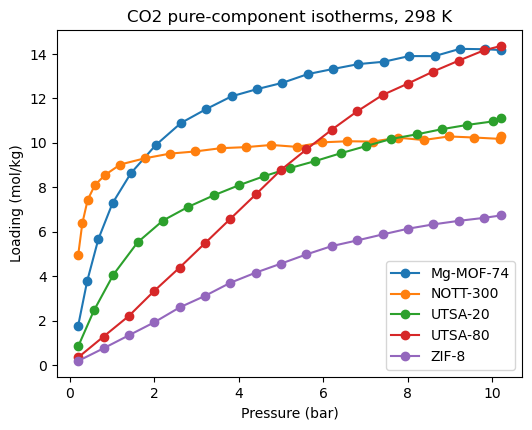

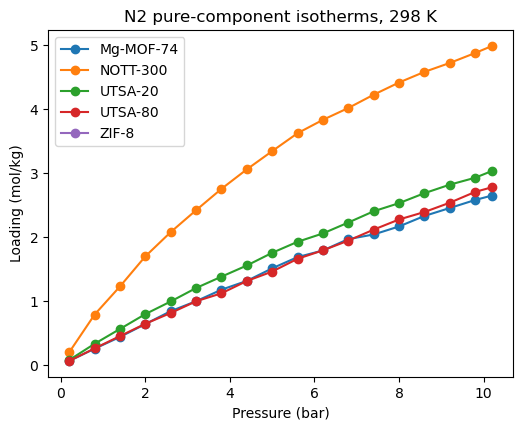

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import ast

P_TO_BAR = 1.0  

co2 = {"Mg-MOF-74": mgMOF74_co2, "NOTT-300": nott300_co2,
       "UTSA-20": utsa20_co2, "UTSA-80": utsa80_co2, "ZIF-8": zif8_co2}
n2  = {"Mg-MOF-74": mgMOF74_n2, "NOTT-300": nott300_n2,
       "UTSA-20": utsa20_n2, "UTSA-80": utsa80_n2, "ZIF-8": zif8_n2}

def isotherm(df):
    kv = dict(zip(df["Key"], df["Value"]))
    iso = kv.get("isotherm")
    if not isinstance(iso, str):  
        return np.array([]), np.array([])
    iso = ast.literal_eval(iso)

    p = np.array(iso["pressure"], float) * P_TO_BAR     # bar
    key = next(k for k in iso if "loading" in k.lower() and "dev" not in k.lower()
               and "unit" not in k.lower())
    q = np.array(iso[key], float)
    units = [str(v) for k, v in iso.items() if "unit" in k.lower()]
    if any("molec" in u.lower() for u in units):
        q = q * float(kv["conversion_factor_molec_uc_to_mol_kg"])

    order = np.argsort(p)
    return p[order], q[order]

for gas, series in (("CO2", co2), ("N2", n2)):
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for name, df in series.items():
        if df is None:
            continue
        p, q = isotherm(df)
        ax.plot(p, q, "o-", label=name)
    ax.set_xlabel("Pressure (bar)")
    ax.set_ylabel("Loading (mol/kg)")
    ax.set_title(f"{gas} pure-component isotherms, 298 K")
    ax.legend()
    plt.show()

- $CO_2$ isotherms

NOTT-300 has the steepest low-pressure isotherm and saturates at about 10 mol/kg from 2 bar onwards, followed by Mg-MOF-74, which levels off near 14 mol/kg. UTSA-80 and ZIF-8 rise almost linearly, which indicates a weak affinity for $CO_2$. UTSA-80 does not saturate and reaches the highest loading at 10 bar (about 14.4 mol/kg), whereas ZIF-8 has the lowest loading over the whole range. At low pressure the isotherms are in the Henry regime ($q \approx K_H P$), so the ordering follows the affinity of the framework for $CO_2$ (NOTT-300 > Mg-MOF-74 > UTSA-20 > UTSA-80 > ZIF-8), while at high pressure it is controlled by the pore volume.

NOTT-300 has the steepest low-pressure isotherm and saturates at about 10 mol/kg from 2 bar, followed by Mg-MOF-74, which levels off near 14 mol/kg. These plateaux correspond to the saturation capacity, reached when the pores are full, and they are set by the available pore volume. UTSA-80 and ZIF-8 rise almost linearly, which indicates a weak affinity for $CO_2$. UTSA-80 does not reach a plateau and has the highest loading at 10 bar (about 14.4 mol/kg), whereas ZIF-8 has the lowest loading over the whole range. At low pressure the isotherms are in the Henry regime ($q \approx K_H P$), so the ordering follows the affinity of the framework for $CO_2$ (NOTT-300 > Mg-MOF-74 > UTSA-20 > UTSA-80 > ZIF-8), while at high pressure it is controlled by the pore volume.

- $N_2$ isotherms 

The $N_2$ loadings are much lower than the $CO_2$ ones and almost linear, because $N_2$ interacts more weakly with the framework. NOTT-300 adsorbs the most $N_2$. No $N_2$ isotherm is shown for ZIF-8: the $N_2$ probe is too large to pass the narrow windows of the rigid structure (POAV = 0), so the cages are treated as inaccessible.

### Question 4
Calculate the $CO_2$ working capacity (WC) for the different structures.

In a PSA/VSA process, the adsorbent is loaded with $CO_2$ at high pressure (adsorption) and then regenerated by lowering the pressure (desorption). The working capacity is the amount of $CO_2$ that is actually recovered during one cycle:

$$WC = q(P_{ads}) - q(P_{des})$$

where:
- $q(P_{ads})$ is the $CO_2$ loading (mol/kg) at the adsorption pressure, the amount captured from the flue gas.
- $q(P_{des})$ is the loading that remains at the desorption pressure, the $CO_2$ that stays in the pores and is not released.

Here the working capacity is estimated from the equilibrium isotherms of Question 3, without simulating the process itself. $P_{ads}$ is taken as the total flue-gas pressure (1 bar) and $P_{des} = 0.2$ bar is the desorption pressure, both at 298 K. The loadings are linearly interpolated between the simulated pressures.

In [21]:
P_ADS, P_DES = 1.0, 0.2  

rows = []
for name, df in co2.items():
    if df is None:
        rows.append((name, np.nan, np.nan, np.nan))
        continue
    p, q = isotherm(df)
    if p.size == 0:
        rows.append((name, np.nan, np.nan, np.nan))
        continue
    q_ads, q_des = np.interp([P_ADS, P_DES], p, q)
    rows.append((name, q_ads, q_des, q_ads - q_des))

wc = pd.DataFrame(rows, columns=["Structure", "q_ads (mol/kg)",
                                 "q_des (mol/kg)", "WC (mol/kg)"])
wc.sort_values("WC (mol/kg)", ascending=False).round(3)

,Structure,q_ads (mol/kg),q_des (mol/kg),WC (mol/kg)
0,Mg-MOF-74,7.221,1.768,5.453
1,NOTT-300,8.769,4.942,3.827
2,UTSA-20,3.948,0.833,3.114
3,UTSA-80,1.586,0.338,1.248
4,ZIF-8,0.944,0.178,0.765


The structures rank as Mg-MOF-74 (5.45) > NOTT-300 (3.83) > UTSA-20 (3.11) > UTSA-80 (1.25) > ZIF-8 (0.77) in working capacity in mol/kg.

This differs from the ranking by uptake at 1 bar. NOTT-300 adsorbs the most at 1 bar (8.77 mol/kg), but it is already highly loaded at 0.2 bar (4.94 mol/kg), so little $CO_2$ is released when the pressure is lowered. Mg-MOF-74 holds only 1.77 mol/kg at 0.2 bar, which gives it the highest working capacity.UTSA-80 and ZIF-8 have a low working capacity because their uptake at 1 bar is low.

This can be explained by the shape of the isotherms of Question 3. The isotherm of NOTT-300 is almost flat above 1 bar, so a large part of its capacity is already used at 0.2 bar and the pressure window releases only 3.83 of the 8.77 mol/kg adsorbed at 1 bar. The isotherm of Mg-MOF-74 is still rising steeply between 0.2 and 1 bar, so most of the adsorbed $CO_2$ is recovered when the pressure is lowered. A strong affinity is therefore useful to capture $CO_2$ at low partial pressure, but too strong a binding is a drawback when the adsorbent has to be regenerated at 0.2 bar. The best material is the one whose isotherm is steep inside the 0.2 to 1 bar window, not the one that is steepest at the origin.

### Question 5
Calculate the $CO_2$/$N_2$ selectivity (S) for the different structures.

In [ ]:

from scipy.optimize import curve_fit, brentq

def langmuir(p, qm, b):
    return qm * b * p / (1 + b * p)

def fit(df):
    p, q = isotherm(df)
    return curve_fit(langmuir, p, q, p0=[max(q), 0.2],
                     bounds=(0, np.inf))[0]

def iast(c, n):
    params = [c, n]
    y = np.array([0.15, 0.85])

    def p0(pi):
        return np.array([np.expm1(pi / qm) / b for qm, b in params])

    pi = brentq(lambda pi: np.sum(y / p0(pi)) - 1, 1e-10, 100)
    pressures = p0(pi)
    x = y / pressures
    q0 = np.array([langmuir(p, *par) for p, par in zip(pressures, params)])
    q = x / np.sum(x / q0)

    return q[0], q[1], (q[0] / q[1]) * (0.85 / 0.15)

results = []

for name in co2:
    if name == "ZIF-8":
        p, q = isotherm(co2[name])
        results.append([name, np.interp(1, p, q), np.nan, np.nan])
    else:
        results.append([name, *iast(fit(co2[name]), fit(n2[name]))])

selectivity_df = pd.DataFrame(
    results, columns=["Structure", "q_CO2", "q_N2", "Selectivity"]
)

display(selectivity_df.round(3))


,Structure,q_CO2,q_N2,Selectivity
0,Mg-MOF-74,1.662,0.251,37.474
1,NOTT-300,4.379,0.450,55.093
2,UTSA-20,0.727,0.326,12.618
3,UTSA-80,0.301,0.269,6.345
4,ZIF-8,0.944,NaN,NaN


Ranking the structures in order of increasing selectivity:

UTSA-80 < UTSA-20 < Mg-MOF-74 < NOTT-300

The CO₂/N₂ selectivity was calculated using Ideal Adsorbed Solution Theory (IAST), based on the pure-component adsorption isotherms obtained from GCMC simulations at 298 K. The flue gas was assumed to contain 15% CO₂ and 85% N₂, at a total adsorption pressure of 1 bar.

The selectivity is defined as:

$S_{\mathrm{CO_2/N_2}}=\frac{q_{\mathrm{CO_2}}}{q_{\mathrm{N_2}}}\times\frac{0.85}{0.15}$

A higher selectivity indicates a stronger preference for CO₂ adsorption over N₂, which is desirable for CO₂ capture from flue gas.

For UTSA-20, a single-site Langmuir fit combined with IAST gives an estimated selectivity of approximately 12.62, indicating preferential CO₂ adsorption. The selectivities of the remaining structures can be calculated using the same procedure to compare their separation performance.

### Question 6
Rank the structures using a WC vs. S plot.

### Question 7
Is the screening model conclusive as to which material performs best in a PSA/VSA process for post-combustion $CO_2$ capture? Discuss the level at which the screening was performed and come up with more complex key performance indicators.

### Question 8
Organization of the report.